# 02 — Baselines classiques

**Question** : quel score un modèle classique, sans réseau de neurones, atteint-il ? C'est la barre que tout modèle de deep learning devra franchir pour justifier sa complexité.

**Pourquoi c'est important** : une baseline faible rend n'importe quel réseau impressionnant. Pour que la comparaison soit honnête, les baselines reçoivent ici le même soin que les réseaux : mêmes données, mêmes fenêtres, hyperparamètres réglés sur la même validation, plusieurs graines.

**Protocole**
- Découpage **par moteur** : 80 % des moteurs pour l'entraînement, 20 % pour la validation. Un découpage par ligne mettrait des cycles voisins du même moteur des deux côtés et donnerait un score excellent et faux.
- Normalisation ajustée sur le train uniquement.
- Cible : la RUL, plafonnée à 125, du dernier cycle de chaque fenêtre.
- Tout est évalué sur la **validation**. Le jeu de test officiel n'apparaît que dans `04_evaluation.ipynb`.

**Métriques** (d = RUL prédite − RUL réelle)
- **RMSE** et **MAE**, en cycles.
- **Score NASA** : somme de `exp(−d/13) − 1` si d < 0 et de `exp(d/10) − 1` sinon. Il pénalise davantage les prédictions trop optimistes, qui peuvent mener à une panne en vol. C'est une somme : il grandit avec le nombre de fenêtres et ne se compare qu'à jeu identique.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Le notebook est rangé dans notebooks/ : on se place à la racine du projet,
# pour que les chemins relatifs (data/raw, results, models) fonctionnent partout.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import set_plot_style

set_plot_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)


def say(text: str) -> None:
    """Affiche une phrase dont les chiffres viennent du code, pas d'une saisie manuelle."""
    from IPython.display import Markdown, display

    display(Markdown(text))

from src.data import prepare
from src.experiments import EXPERIMENTS
from src.train import apply_overrides
from src.utils import load_config


def bundle_for(name: str, **data_overrides) -> dict:
    """Données (découpage, normalisation, fenêtres) de l'expérience `name` du registre."""
    _, base, overrides = EXPERIMENTS[name]
    cfg = apply_overrides(load_config(base), overrides | {f"data.{k}": v for k, v in data_overrides.items()})
    return prepare(cfg["data"], cfg["seed"])

from src.baselines import BOOSTING, FOREST, forest_params, run_baselines, window_features
from src.data import STATE_NAMES

fd001, fd004 = bundle_for("lstm_fd001"), bundle_for("multitask_fd004")  # fenêtre W = 30
for nom, bundle in [("FD001", fd001), ("FD004", fd004)]:
    print(f"{nom} : {bundle['train_df']['unit'].nunique()} moteurs train / {bundle['val_df']['unit'].nunique()} validation, "
          f"fenêtres train {bundle['train']['X'].shape}, validation {bundle['val']['X'].shape}")

FD001 : 80 moteurs train / 20 validation, fenêtres train (14070, 30, 14), validation (3661, 30, 14)
FD004 : 199 moteurs train / 50 validation, fenêtres train (43376, 30, 14), validation (10652, 30, 14)


## 1. Quatre baselines, réglages par défaut (W = 30)

1. **Moyenne du train** : la même prédiction pour tout le monde. C'est le plancher absolu.
2. **Régression linéaire** sur les 14 capteurs du **dernier cycle** de la fenêtre, sans historique.
3. **Random Forest** sur 4 caractéristiques par capteur, extraites de la fenêtre : moyenne, écart-type, pente et dernière valeur, soit 56 variables.
4. **Gradient boosting** sur les mêmes 56 variables.

**Attente** : si l'historique compte (conclusion du notebook 01), les modèles 3 et 4 doivent faire nettement mieux que le modèle 2.

Caractéristiques de fenêtre : (14070, 56)


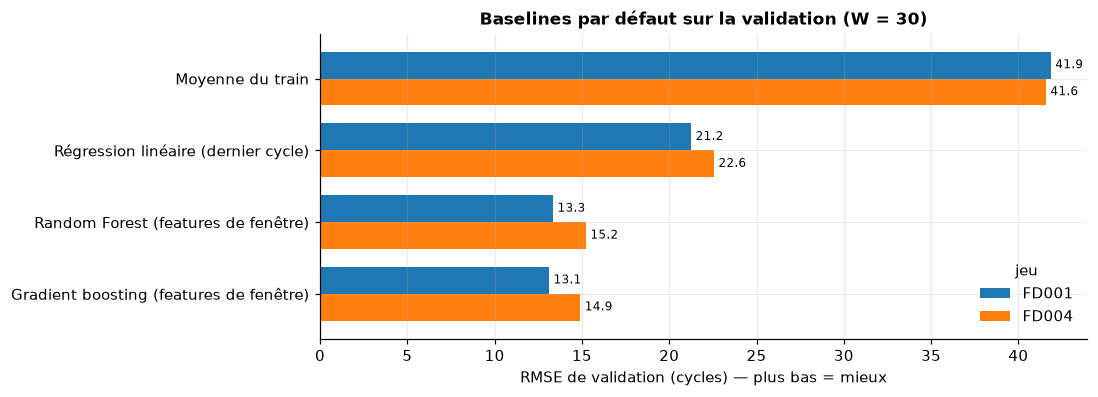

Passer d'un seul cycle (régression linéaire) à des caractéristiques de fenêtre (Random Forest) fait baisser la RMSE de 21.2 à 13.3 sur FD001 et de 22.6 à 15.2 sur FD004 : l'attente est vérifiée, l'historique compte.

In [2]:
print("Caractéristiques de fenêtre :", window_features(fd001["train"]["X"]).shape)

defaut = pd.concat([
    run_baselines(fd001["train"], {"FD001": fd001["val"]}),
    run_baselines(fd004["train"], {"FD004": fd004["val"]}),
]).drop(columns="pred")
rmse = defaut.pivot(index="modèle", columns="jeu", values="rmse").sort_values("FD001", ascending=False)

ax = rmse.plot.barh(figsize=(9, 3.6), width=0.75)
ax.set_xlabel("RMSE de validation (cycles) — plus bas = mieux")
ax.set_ylabel("")
ax.set_title("Baselines par défaut sur la validation (W = 30)")
ax.invert_yaxis()
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3, fontsize=8)
plt.show()

lin, rf = rmse.loc["Régression linéaire (dernier cycle)"], rmse.loc[FOREST]
say(f"Passer d'un seul cycle (régression linéaire) à des caractéristiques de fenêtre (Random Forest) fait baisser la RMSE "
    f"de {lin['FD001']:.1f} à {rf['FD001']:.1f} sur FD001 et de {lin['FD004']:.1f} à {rf['FD004']:.1f} sur FD004 : "
    f"l'attente est vérifiée, l'historique compte.")

Deux effets sont mélangés dans cette comparaison : l'historique (fenêtre contre dernier cycle) et la non-linéarité (forêt contre modèle linéaire). On ne les sépare pas ici.

## 2. Réglage du Random Forest

Les réseaux du notebook 03 bénéficient d'une recherche d'hyperparamètres. Pour ne pas avantager les réseaux, la forêt est réglée elle aussi, sur la même validation et avec la fenêtre retenue pour les réseaux (W = 40). La grille (`python -m src.baselines`) porte sur deux paramètres :
- `min_samples_leaf` : taille minimale d'une feuille (régularisation) ;
- `max_features` : part des variables essayées à chaque coupure (diversité des arbres).

In [3]:
tuning = pd.read_csv("results/forest_tuning.csv")
display(tuning.pivot_table(index=["jeu", "min_samples_leaf"], columns="max_features", values="rmse").round(2))

for jeu, t in tuning.groupby("jeu"):
    best = t.sort_values("rmse").iloc[0]
    say(f"**{jeu}** : meilleur réglage `min_samples_leaf = {best['min_samples_leaf']}`, `max_features = {best['max_features']}` "
        f"(RMSE {best['rmse']:.2f}) ; l'écart entre le meilleur et le moins bon réglage est de {t['rmse'].max() - t['rmse'].min():.2f} cycle.")

max_features             0.33    1.0   sqrt
jeu   min_samples_leaf                     
FD001 1                 11.13  11.61  11.32
      5                 11.10  11.60  11.23
      15                11.22  11.76  11.39
FD004 1                 13.63  13.96  13.86
      5                 13.49  13.88  13.76
      15                13.51  13.80  13.82

**FD001** : meilleur réglage `min_samples_leaf = 5`, `max_features = 0.33` (RMSE 11.10) ; l'écart entre le meilleur et le moins bon réglage est de 0.66 cycle.

**FD004** : meilleur réglage `min_samples_leaf = 5`, `max_features = 0.33` (RMSE 13.49) ; l'écart entre le meilleur et le moins bon réglage est de 0.46 cycle.

`max_features` est le paramètre qui compte : n'essayer qu'une partie des variables à chaque coupure décorrèle les arbres. La valeur par défaut de scikit-learn pour la régression (toutes les variables, colonne `1.0`) n'est le meilleur choix dans aucune ligne du tableau.

## 3. Baselines réglées, 5 graines (W = 40)

Une forêt dépend elle aussi d'une graine. On l'entraîne 5 fois, comme les réseaux, pour disposer d'une moyenne et d'un écart-type comparables.

In [4]:
rows = []
for jeu, name in [("FD001", "gru_best_fd001"), ("FD004", "multitask_w40_fd004")]:
    bundle = bundle_for(name)  # mêmes données que le réseau retenu : W = 40
    for seed in range(5):
        res = run_baselines(bundle["train"], {jeu: bundle["val"]}, seed=seed, forest=forest_params(jeu))
        rows.append(res.drop(columns="pred").assign(seed=seed))
regle = pd.concat(rows)
regle.to_csv("results/baselines_validation.csv", index=False)

resume = regle.groupby(["jeu", "modèle"])["rmse"].agg(["mean", "std"]).round(2)
display(resume.sort_values(["jeu", "mean"], ascending=[True, False]))

BARRE = regle.groupby(["jeu", "modèle"])["rmse"].mean().groupby("jeu").min()
for jeu in BARRE.index:
    meilleur = resume.loc[jeu]["mean"].idxmin()
    say(f"**Barre à franchir sur {jeu} : RMSE {BARRE[jeu]:.2f}** ({meilleur}).")

mean   std
jeu   modèle                                              
FD001 Moyenne du train                         41.76  0.00
      Régression linéaire (dernier cycle)      21.37  0.00
      Gradient boosting (features de fenêtre)  11.65  0.10
      Random Forest (features de fenêtre)      11.14  0.05
FD004 Moyenne du train                         41.79  0.00
      Régression linéaire (dernier cycle)      22.64  0.00
      Random Forest (features de fenêtre)      13.57  0.05
      Gradient boosting (features de fenêtre)  13.53  0.04

**Barre à franchir sur FD001 : RMSE 11.14** (Random Forest (features de fenêtre)).

**Barre à franchir sur FD004 : RMSE 13.53** (Gradient boosting (features de fenêtre)).

## 4. Répartition des classes d'état

Le modèle final prédira aussi l'état du moteur : **sain** (RUL > 80), **à surveiller** (30 < RUL ≤ 80), **critique** (RUL ≤ 30). Les seuils sont un choix métier posé a priori, pas un résultat. Les proportions servent à pondérer la perte de classification.

In [5]:
parts = pd.DataFrame({
    nom: np.bincount(bundle["train"]["state"]) / len(bundle["train"]["state"])
    for nom, bundle in [("FD001", fd001), ("FD004", fd004)]
}, index=STATE_NAMES)
display(parts.map("{:.1%}".format))
say(f"La classe critique ne représente que {parts.loc['critique'].min():.0%} à {parts.loc['critique'].max():.0%} des fenêtres : "
    f"sans pondération, un classifieur pourrait l'ignorer sans que sa perte en souffre beaucoup.")

,FD001,FD004
sain,53.9%,62.8%
à surveiller,28.4%,22.9%
critique,17.6%,14.2%


La classe critique ne représente que 14% à 18% des fenêtres : sans pondération, un classifieur pourrait l'ignorer sans que sa perte en souffre beaucoup.

## 5. Ce qu'il faut retenir

- La barre à franchir est celle des baselines **réglées** (section 3), pas celle des réglages par défaut.
- Limite : la grille de la forêt est petite (9 combinaisons) et le gradient boosting n'est pas réglé. La barre pourrait donc être encore un peu plus haute.
- Limite : régler un hyperparamètre sur la validation puis mesurer sur cette même validation donne un score légèrement optimiste. C'est vrai aussi pour les réseaux ; le jeu de test, jamais utilisé pour un choix, tranchera.

Suite : `03_experiences.ipynb` teste les hypothèses sur les réseaux et les confronte à cette barre.